# Does trial-mode entropy explain the neural correlates of LD1?

**Question.** High-LD1 sessions show a larger Fano-factor quench and less noise correlation (`lda1_neural_summary.ipynb`). On the behavioural side, mode-use entropy — how evenly a session spreads its trials over the trial modes — falls along LD1 (`fig_engagement_syllables`, panel f: ρ = −0.37 across mice). Is trial-mode entropy the behavioural variable behind the neural effects: do sessions whose trials are more varied have less quench and more correlated variability?

**Approach — the same machinery as the LD1 grid and the behavioural-axes check** (`run_behavior_axes.py`), so every number is comparable cell by cell:
* the same cached metric tables and cohort (`run_behavior_axes.config()` = the config cell of `lda1_neural_summary`; `apply_cohort(..., 'common')`);
* the same ten tests (`nm.GRID`: firing rate, Fano factor, $r_{SC}$ × baseline / post / response magnitude / onset);
* the same statistic (`nm.age_effect_test`: GLM slope with region and trial-count covariates, 2000 permutations that shuffle the predictor across **sessions**, partial-correlation BF10), corrected within each metric.

Three steps:
1. **Screen** — trial-mode entropy against LD1 (and engagement switching) on the neural sessions.
2. **Grid** — entropy in place of LD1, ten tests, next to LD1 on the identical rows.
3. **Mediation** — in every cell where either predictor is significant, refit with both: LD1 controlling for entropy, and entropy controlling for LD1. If entropy is the mechanism, LD1's partial r shrinks when entropy is controlled while entropy survives control for LD1.

**Trial-mode entropy** is computed exactly as in `fig_engagement_syllables` (panel f), on the LDA file's sessions: per session, the entropy of the trial-mode labels over `N_SUB` random subsamples of the same number of trials (the smallest session's count), averaged, divided by log K. Trials without a mode are left out. Equal trial counts matter: plug-in entropy grows with sample size.

**Which LD1.** The cached neural tables carry the LD1 they were built with, an older embedding that correlates −0.88 with the current one (opposite sign). The behavioural figures, including the entropy–LD1 relation, use the current file, so this notebook replaces the cached column with it by default (`LD1_SOURCE`). The LD1 rows here are therefore not the numbers in `lda1_neural_summary`, and the sign of every LD1 slope is flipped relative to it.

**Caveat.** Entropy is a session-level behavioural variable, like LD1, so the permutation p (sessions shuffled) is the one to read; BF10 is computed at the neuron / session-region level and is inflated the same way as in the LD1 grid.

In [1]:
import sys, pathlib, importlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr

# this notebook lives in paper-individuality/neural, next to lda1_neural_metrics.py
ROOT = next(p / sub for p in [pathlib.Path.cwd().resolve(), *pathlib.Path.cwd().resolve().parents]
            for sub in ('', 'neural', 'paper-individuality/neural') if (p / sub / 'lda1_neural_metrics.py').exists())
PI = ROOT.parent
for p in [str(PI), str(ROOT)]:
    if p not in sys.path:
        sys.path.insert(0, p)
# the LDA file was pickled under numpy 2; under numpy 1 its module paths need aliasing to unpickle
try:
    import numpy._core.numeric  # noqa: F401  (numpy >= 2)
except ModuleNotFoundError:
    import numpy.core.numeric, numpy.core.multiarray
    for name, mod in [('numpy._core.numeric', np.core.numeric), ('numpy._core.multiarray', np.core.multiarray)]:
        sys.modules[name] = mod
import paper_style as ps
import lda1_neural_metrics as nm
import session_axes as sa
import run_behavior_axes as rba
for m in (nm, sa, rba):
    importlib.reload(m)
ps.use('paper')
pd.set_option('display.width', 200)

paper_style: paper mode, spines=lb, font 8 pt, panels 3.4x2.4 in, save 400 dpi


## Parameters

In [2]:
TRIAL_MODES = PI / '3_trial_modes' / 'trial_modes_8_k_10_bin_syllables_02-10-2026' / 'trials.pqt'   # as fig_engagement_syllables
N_SUB = 200                      # equal-count subsamples per session (as fig_engagement_syllables)
SEED = 0
ENTROPY_CACHE = ROOT / 'lda1_tables' / f'session_mode_entropy_{TRIAL_MODES.parent.name}_ldasessions.pqt'
PREDICTOR = 'H_modes'
COMPARE = ['lda_1', 'switch_rate']   # reference predictors run on the same rows
# WHICH LD1. The cached neural tables carry the lda_1 they were computed with (an older embedding: r = -0.88 with
# the current file, i.e. sign-flipped and not identical), and attach_lda never overwrites it -- by design, so the
# published neural numbers stay reproducible. Trial-mode entropy is compared with LD1 in the behavioural figures
# using the CURRENT file, so 'current' (default) replaces the cached column with it; 'cached' keeps the old one.
LD1_SOURCE = 'current'

## 1. Data

The neural tables (cached), the cohort, and the predictors attached by session: LD1 (by `apply_cohort`), the behavioural axes (`session_axes`, which carries `switch_rate`), and trial-mode entropy (below).

In [3]:
cfg = rba.config()
cfg['LD1_SOURCE'] = LD1_SOURCE
print(f"cache tag: {nm.cache_tag(cfg)} | {cfg['N_PERM']} permutations | FDR family: {cfg['FDR_FAMILY']}")
tables = nm.apply_cohort(nm.load_tables(cfg=cfg), cfg, 'common')
tables = sa.attach_axes(tables, sa.session_axes())
# LD1: handled by nm.apply_cohort through cfg['LD1_SOURCE'] (set from LD1_SOURCE in the parameters)


cache tag: lda1_neural_pr90_fr10_sess | 2000 permutations | FDR family: metric
loaded 'lda1_neural_pr90_fr10_sess_20-09-2026': curves (1957), ff (18945), fr (21497), rsc (647), sessions (253), time (90)
LDA file: mouse_LDA_5_bins_raw_shrink0.5_wmouse_360_02-10-2026
  attached lda_2, lda_3 to the metric tables
cohort 'common': fr 17524 rows / 199 sessions | ff 15389 rows / 199 sessions | rsc 540 rows / 198 sessions
session axes: 244 sessions from cache session_axes.pqt
  attached frac_engaged, n_trials_beh, p_engaged, performance, rt_mean, rt_median, rt_sd, switch_rate
lda_1 replaced by the current LDA file; r(cached, current) = -0.879 over 244 sessions


In [4]:
def entropy(counts):
    p = counts[counts > 0] / counts.sum()
    return -(p * np.log(p)).sum()

def mode_entropy(sessions, path=TRIAL_MODES, n_sub=N_SUB, seed=SEED, cache=ENTROPY_CACHE):
    # per-session trial-mode entropy over equal-count subsamples, / log K -- as fig_engagement_syllables.
    # ONLY the LDA file's sessions, as there: the subsample size is the smallest session's trial count, and the
    # trial-mode file also holds short sessions (down to 40 trials) that would set it far lower
    if cache.exists():
        return pd.read_parquet(cache)
    mt = pd.read_parquet(path, columns=['session', 'trial_id', 'trial_cluster']).dropna(subset=['trial_cluster'])
    mt = mt[mt['session'].isin(set(sessions))]
    ids = np.sort(mt['trial_cluster'].unique()).astype(int)
    K, n_trials = len(ids), int(mt.groupby('session').size().min())
    rng = np.random.default_rng(seed)
    rows = []
    for s, g in mt.groupby('session'):
        lab = g['trial_cluster'].to_numpy().astype(int)
        sub = [entropy(np.bincount(rng.choice(lab, n_trials, replace=False), minlength=ids.max() + 1))
               for _ in range(n_sub)]
        rows.append(dict(session=s, H_modes=np.mean(sub) / np.log(K), n_mode_trials=len(lab)))
    out = pd.DataFrame(rows)
    out.attrs.update(K=K, n_trials=n_trials)
    out.to_parquet(cache)
    print(f'{len(out)} sessions, K = {K} modes, subsampled to {n_trials} trials; cached to {cache.name}')
    return out

H = mode_entropy(nm.load_lda_frame(cfg)['session'])
print(f'{len(H)} sessions; check against fig_engagement_syllables (260 sessions, 372 trials): '
      f"rho(H, LD1) = {spearmanr(H.merge(nm.load_lda_frame(cfg), on='session')[['H_modes', 'lda_1']]).statistic:.3f} (figure: -0.241)")
h_map = dict(zip(H['session'], H[PREDICTOR]))
for k, t in tables.items():
    if isinstance(t, pd.DataFrame) and 'session' in t.columns:
        tables[k] = t.assign(**{PREDICTOR: t['session'].map(h_map)})

# every predictor is tested on the SAME rows: sessions that have all of them
need = [PREDICTOR] + COMPARE
for k in ['fr', 'ff', 'rsc']:
    before = tables[k]['session'].nunique()
    tables[k] = tables[k].dropna(subset=need)
    print(f"{k:4s}: {tables[k]['session'].nunique()} of {before} sessions have {', '.join(need)}")

260 sessions; check against fig_engagement_syllables (260 sessions, 372 trials): rho(H, LD1) = -0.241 (figure: -0.241)
fr  : 190 of 199 sessions have H_modes, lda_1, switch_rate
ff  : 190 of 199 sessions have H_modes, lda_1, switch_rate
rsc : 189 of 198 sessions have H_modes, lda_1, switch_rate


## 2. Screen: is trial-mode entropy related to LD1 here?

On the neural sessions (one point per session, and per mouse). An axis that does not track LD1 cannot be what LD1 measures; it could still relate to the neural metrics on its own.

In [5]:
sess = tables['ff'].groupby('session').agg(lda_1=('lda_1', 'first'), H_modes=(PREDICTOR, 'first'),
                                           switch_rate=('switch_rate', 'first'), mouse_name=('mouse_name', 'first'))
mouse = sess.groupby('mouse_name').mean(numeric_only=True)
rows = []
for x, y in [('lda_1', 'H_modes'), ('switch_rate', 'H_modes'), ('lda_1', 'switch_rate')]:
    for unit, d in [('session', sess), ('mouse', mouse)]:
        r = spearmanr(d[x], d[y], nan_policy='omit')
        rows.append(dict(x=x, y=y, unit=unit, n=int(d[[x, y]].dropna().shape[0]), rho=r.statistic, p=r.pvalue))
SCREEN = pd.DataFrame(rows)
SCREEN.round(4)

,x,y,unit,n,rho,p
0,lda_1,H_modes,session,190,-0.2488,0.0005
1,lda_1,H_modes,mouse,54,-0.3244,0.0167
2,switch_rate,H_modes,session,190,0.1057,0.1466
3,switch_rate,H_modes,mouse,54,0.2492,0.0691
4,lda_1,switch_rate,session,190,-0.2690,0.0002
5,lda_1,switch_rate,mouse,54,-0.3442,0.0108


## 3. The grid: trial-mode entropy in place of LD1

Ten tests per predictor, each corrected within its metric. LD1 and switch rate are re-run on the identical rows (sessions with every predictor), so the LD1 numbers here can differ slightly from the summary notebook's.

In [6]:
RES = {}
for pred in COMPARE[:1] + [PREDICTOR] + COMPARE[1:]:
    print(f'\n=== predictor: {pred} ===')
    RES[pred] = nm.run_tests(tables, cfg, verbose=False, predictor=pred)
    print(nm.results_table(RES[pred], p_floor=1.0 / cfg['N_PERM']))


=== predictor: lda_1 ===


metric            test                          unit       n  n_sess     slope   r_part      BF10      evidence    p_perm  q_metric    q_all   q_Holm      
                                                                                                                         <-- reported         
Firing rate       Baseline                    neuron   16448     190    0.0139   0.0404  6.08e+03     strong H1    0.0460    0.0920   0.0688   0.1380      
Firing rate       Post-stimulus               neuron   16448     190    0.0074   0.0218     0.473  inconclusive    0.2240    0.2340   0.2574   0.4480      
Firing rate       Response magnitude          neuron   16448     190    0.0410   0.0146    0.0552     strong H0    0.2340    0.2340   0.2574   0.4480      
Firing rate       Response onset              neuron   12823     190    0.0018   0.0793  2.55e+15     strong H1    0.0020    0.0080   0.0055   0.0080     *
Fano factor       Baseline                    neuron   14569     190   -0.003

metric            test                          unit       n  n_sess     slope   r_part      BF10      evidence    p_perm  q_metric    q_all   q_Holm      
                                                                                                                         <-- reported         
Firing rate       Baseline                    neuron   16448     190   -0.2681  -0.0118    0.0308     strong H0    0.5420    0.7227   0.6624   1.0000      
Firing rate       Post-stimulus               neuron   16448     190   -0.2493  -0.0112    0.0271     strong H0    0.5160    0.7227   0.6624   1.0000      
Firing rate       Response magnitude          neuron   16448     190   -3.5270  -0.0190     0.187   moderate H0    0.0930    0.3720   0.2046   0.3720      
Firing rate       Response onset              neuron   12823     190   -0.0103  -0.0069     0.015     strong H0    0.7675    0.7675   0.8442   1.0000      
Fano factor       Baseline                    neuron   14569     190   -0.036

metric            test                          unit       n  n_sess     slope   r_part      BF10      evidence    p_perm  q_metric    q_all   q_Holm      
                                                                                                                         <-- reported         
Firing rate       Baseline                    neuron   16448     190   -2.0802  -0.0296      12.3     strong H1    0.0980    0.1307   0.1348   0.1960      
Firing rate       Post-stimulus               neuron   16448     190   -1.6144  -0.0233     0.811  inconclusive    0.1445    0.1445   0.1766   0.1960      
Firing rate       Response magnitude          neuron   16448     190  -11.5166  -0.0200     0.253   moderate H0    0.0620    0.1240   0.1348   0.1860      
Firing rate       Response onset              neuron   12823     190   -0.2908  -0.0621  4.67e+08     strong H1    0.0120    0.0480   0.0907   0.0480     *
Fano factor       Baseline                    neuron   14569     190    0.382

In [7]:
cmp_ = pd.concat({p: r.set_index(['metric', 'test'])[['r_partial', 'p_perm', 'q_fdr']] for p, r in RES.items()}, axis=1)
cmp_.round(4)

lda_1                   H_modes                 switch_rate                
                                     r_partial  p_perm   q_fdr r_partial  p_perm   q_fdr   r_partial  p_perm   q_fdr
metric            test                                                                                              
Firing rate       Baseline              0.0404  0.0460  0.0920   -0.0118  0.5420  0.7227     -0.0296  0.0980  0.1307
                  Post-stimulus         0.0218  0.2240  0.2340   -0.0112  0.5160  0.7227     -0.0233  0.1445  0.1445
                  Response magnitude    0.0146  0.2340  0.2340   -0.0190  0.0930  0.3720     -0.0200  0.0620  0.1240
                  Response onset        0.0793  0.0020  0.0080   -0.0069  0.7675  0.7675     -0.0621  0.0120  0.0480
Fano factor       Baseline             -0.0222  0.3225  0.3225   -0.0031  0.8905  0.8905      0.0106  0.6095  0.6095
                  Post-stimulus        -0.0782  0.0035  0.0047    0.0239  0.3550  0.4733      0.0411  0.0915  0.1830
                  Response magnitude    0.0749  0.0000  0.0000   -0.0585  0.0020  0.0040     -0.0344  0.0365  0.1460
                  Response onset       -0.0458  0.0005  0.0010    0.0421  0.0010  0.0040      0.0168  0.1725  0.2300
Noise correlation Baseline             -0.1681  0.0180  0.0270    0.0777  0.2605  0.2605      0.1048  0.0920  0.0920
                  Post-stimulus        -0.2176  0.0005  0.0015    0.1307  0.0490  0.0735      0.1483  0.0165  0.0495
                  Response magnitude    0.1123  0.0500  0.0500   -0.1201  0.0300  0.0735     -0.0986  0.0750  0.0920

## 4. Mediation: does entropy account for the LD1 effect, or the other way round?

For every cell where LD1 **or** entropy is significant (session-level permutation p < α), both are fitted together: LD1 with entropy as an extra covariate, and entropy with LD1 as an extra covariate. `shrinkage` = how much LD1's partial r shrinks when entropy is controlled (1 = fully explained, 0 = untouched).

In [8]:
def both_ways(tables, cfg, a, b, cells):
    rows = []
    for metric, test in cells:
        tbl, y_col, _, _, region_col, covars = nm.GRID[(metric, test)]
        df = tables[tbl]
        fit = lambda pred, extra: nm.age_effect_test(df, y_col, predictor=pred, region_col=region_col,
                                                     extra_covars=tuple(covars) + extra,
                                                     n_perm=cfg['N_PERM'], seed=cfg['SEED'])
        a0, b0, a1, b1 = fit(a, ()), fit(b, ()), fit(a, (b,)), fit(b, (a,))
        rows.append(dict(metric=metric, test=test, n=a1['n'],
                         **{f'r_{a}': a0['r_partial'], f'p_{a}': a0['p_perm'],
                            f'r_{a}|{b}': a1['r_partial'], f'p_{a}|{b}': a1['p_perm'],
                            f'r_{b}': b0['r_partial'], f'p_{b}': b0['p_perm'],
                            f'r_{b}|{a}': b1['r_partial'], f'p_{b}|{a}': b1['p_perm']},
                         shrinkage_of_a=1 - abs(a1['r_partial']) / abs(a0['r_partial'])))
    return pd.DataFrame(rows)

sig = lambda p: set(map(tuple, RES[p].loc[RES[p]['p_perm'] < cfg['ALPHA'], ['metric', 'test']].to_numpy()))
CELLS = sorted(sig('lda_1') | sig(PREDICTOR), key=lambda c: (nm.METRIC_ROWS.index(c[0]), nm.TEST_COLS.index(c[1])))
MED = both_ways(tables, cfg, 'lda_1', PREDICTOR, CELLS)
MED.round(4)

,metric,test,n,r_lda_1,p_lda_1,r_lda_1|H_modes,p_lda_1|H_modes,r_H_modes,p_H_modes,r_H_modes|lda_1,p_H_modes|lda_1,shrinkage_of_a
0,Firing rate,Baseline,16448,0.0404,0.0460,0.0387,0.0435,-0.0118,0.5420,0.0021,0.8985,0.0424
1,Firing rate,Response onset,12823,0.0793,0.0020,0.0818,0.0005,-0.0069,0.7675,0.0213,0.3755,-0.0315
2,Fano factor,Post-stimulus,14569,-0.0782,0.0035,-0.0746,0.0030,0.0239,0.3550,-0.0037,0.8775,0.0465
3,Fano factor,Response magnitude,14569,0.0749,0.0000,0.0582,0.0010,-0.0585,0.0020,-0.0345,0.0215,0.2231
4,Fano factor,Response onset,14534,-0.0458,0.0005,-0.0331,0.0105,0.0421,0.0010,0.0278,0.0140,0.2775
5,Noise correlation,Baseline,509,-0.1681,0.0180,-0.1506,0.0215,0.0777,0.2605,0.0179,0.7905,0.1042
6,Noise correlation,Post-stimulus,509,-0.2176,0.0005,-0.1841,0.0035,0.1307,0.0490,0.0567,0.3690,0.1539
7,Noise correlation,Response magnitude,509,0.1123,0.0500,0.0742,0.1790,-0.1201,0.0300,-0.0856,0.1015,0.3392


## 5. Figure

Top: the two response-magnitude cells the question is about — Fano-factor quench and $r_{SC}$ quench — against trial-mode entropy, one point per session (session mean of the neuron / session-region values, for display only), coloured by LD1; the annotated r and p are the test's partial r and session-level permutation p (no fit line: the session means are for display and need not agree with the neuron-level GLM in sign). Bottom: for every cell where either predictor is significant, LD1's partial r alone and with entropy controlled, and entropy's alone and with LD1 controlled (filled = p < α).

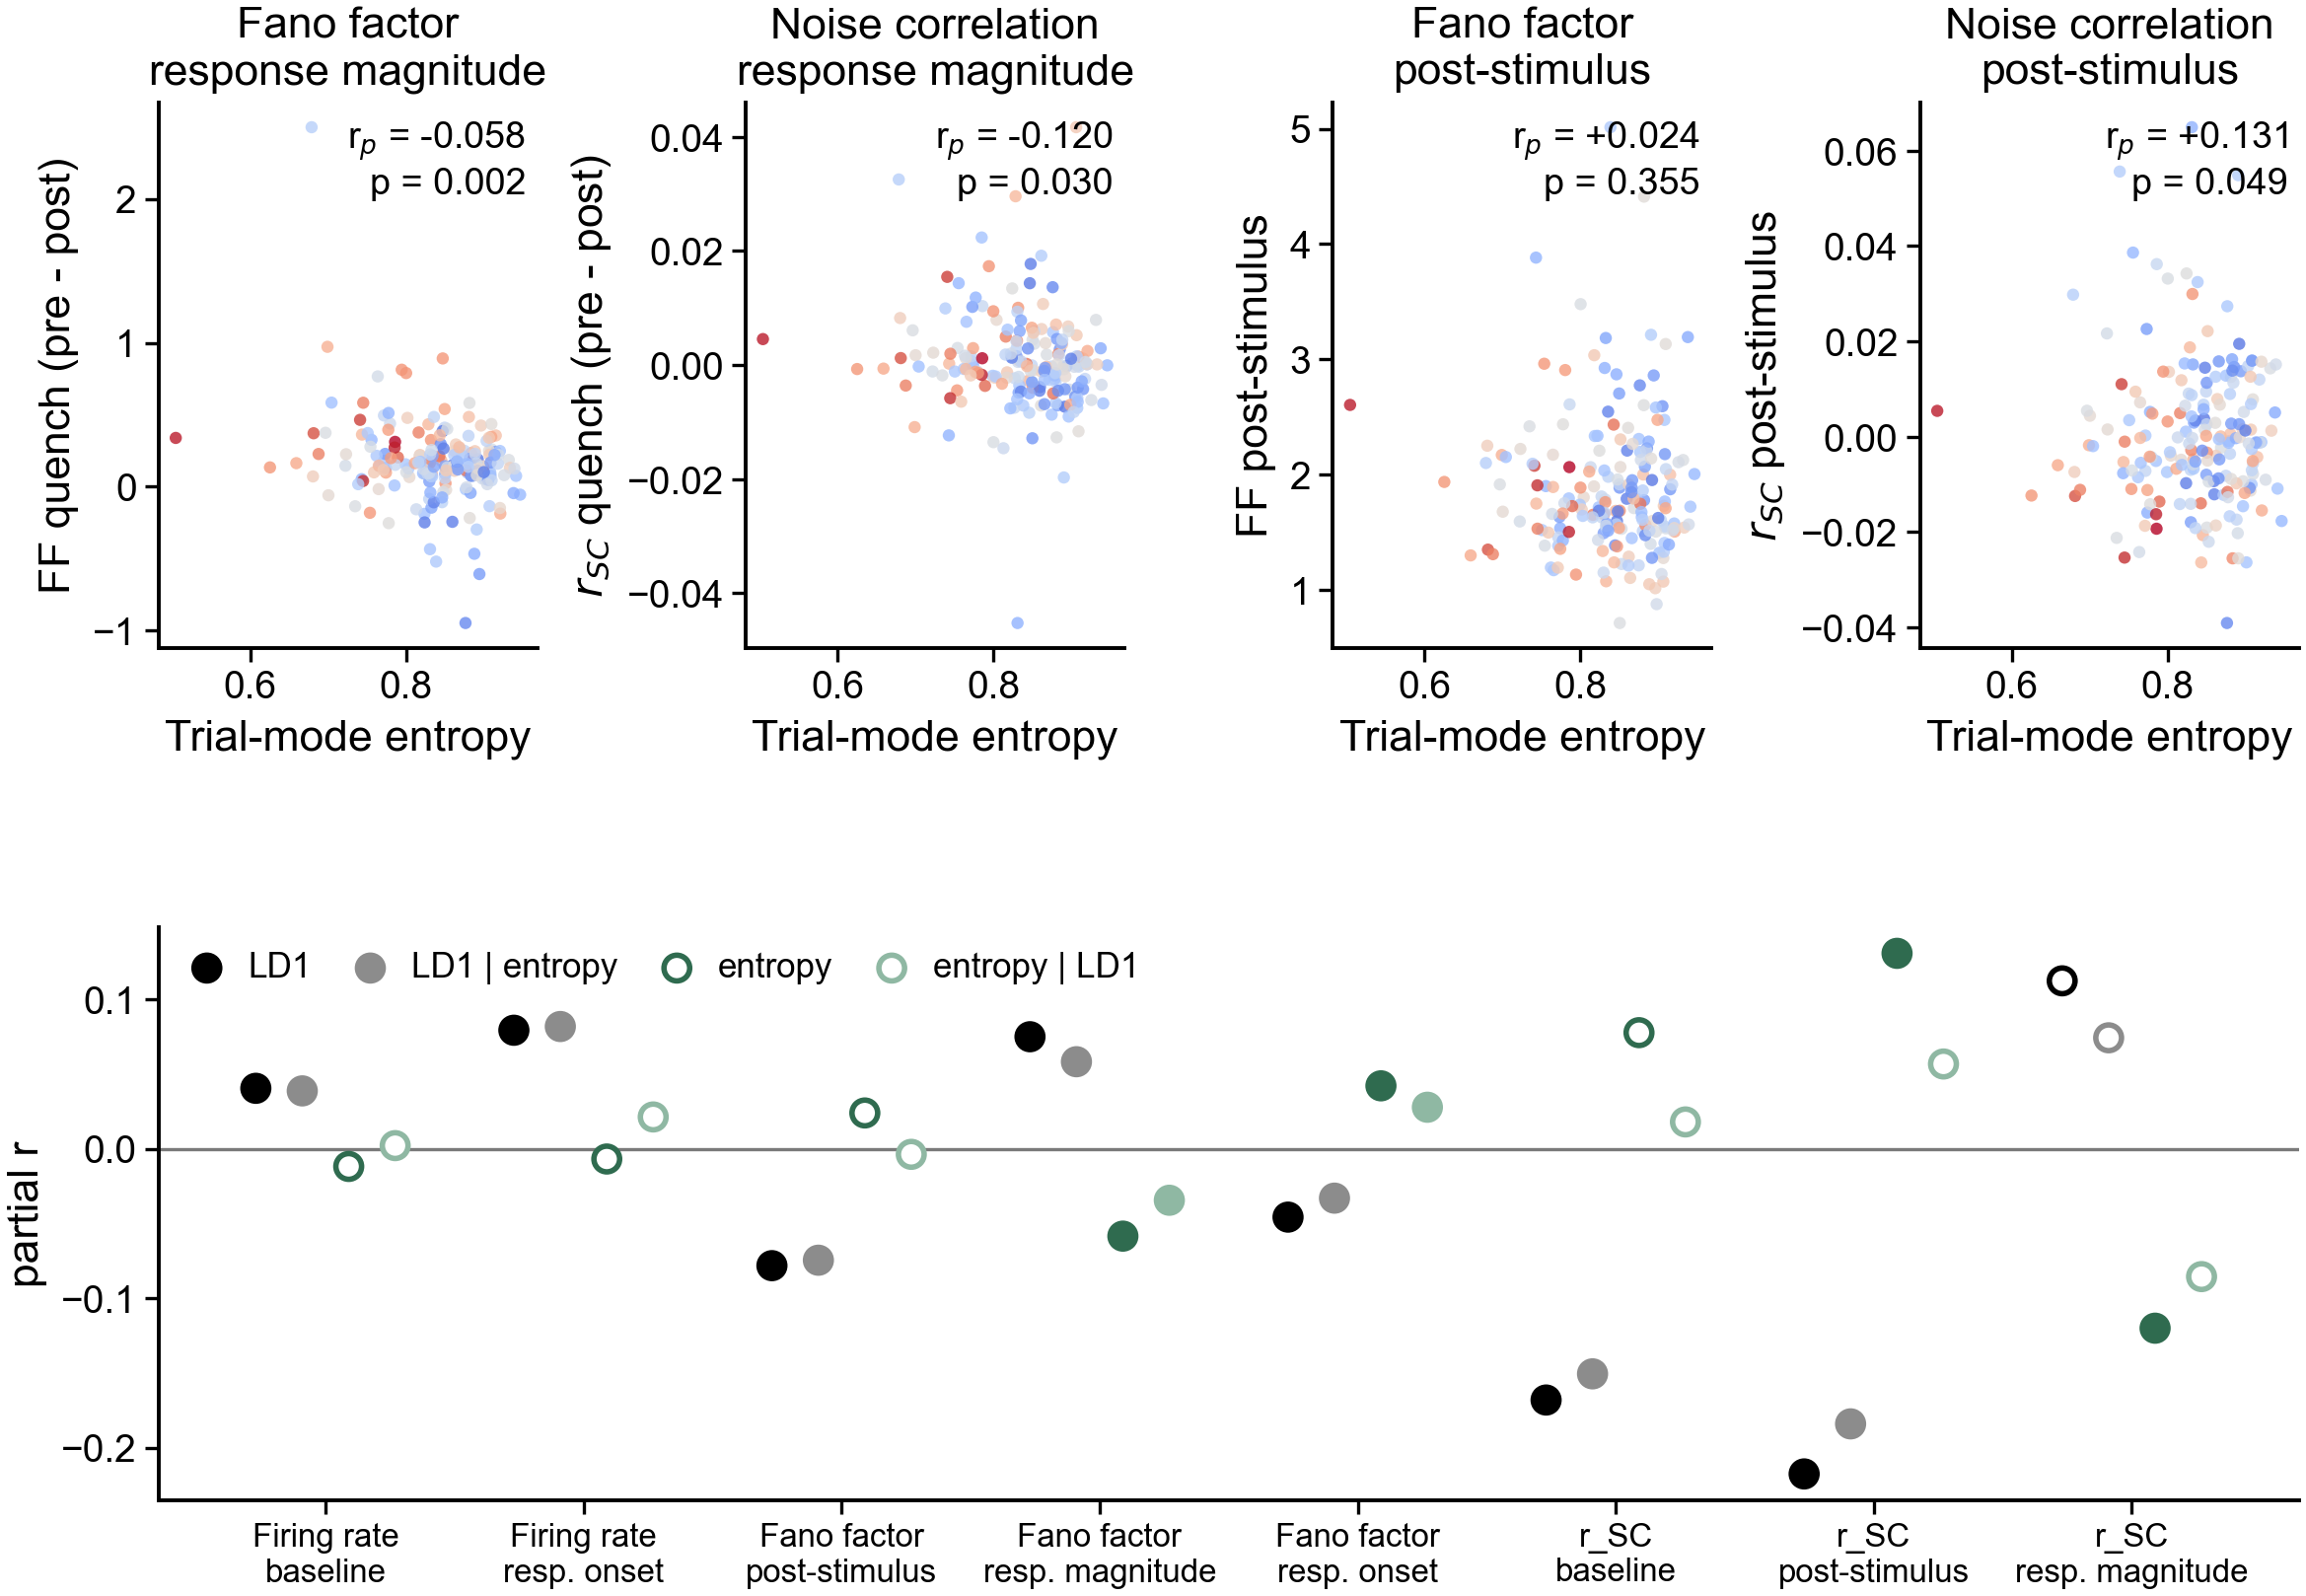

not saved (ps.SAVE_FIGURES is False): figures/neural_mode_entropy_11-10-2026.png, figures/neural_mode_entropy_11-10-2026.svg   -- ps.saving(True) to write, or pass save=True


[]

In [9]:
SHOW = [('Fano factor', 'Response magnitude'), ('Noise correlation', 'Response magnitude'),
        ('Fano factor', 'Post-stimulus'), ('Noise correlation', 'Post-stimulus')]
norm = ps.ld1_norm(sess['lda_1'].to_numpy())
fig = plt.figure(figsize=(7.0, 4.6))
gs = fig.add_gridspec(2, len(SHOW), height_ratios=[1, 1.05], hspace=0.5, wspace=0.55)
for j, cell in enumerate(SHOW):
    ax = fig.add_subplot(gs[0, j])
    tbl, y_col, disp, ylabel, *_ = nm.GRID[cell]
    d = tables[tbl].groupby('session').agg(y=(disp, 'mean'), x=(PREDICTOR, 'first'), c=('lda_1', 'first'))
    ax.scatter(d['x'], d['y'], s=5, lw=0, alpha=0.8, color=ps.LD1_CMAP(norm(d['c'].to_numpy())))
    r = RES[PREDICTOR].set_index(['metric', 'test']).loc[cell]
    # no fit line: the test is a neuron / session-region GLM with region covariates, and a line through these
    # session means can disagree with it in sign; the annotated r_p and p are the test's
    ax.text(0.97, 0.97, f"r$_p$ = {r['r_partial']:+.3f}\np = {r['p_perm']:.3f}", transform=ax.transAxes,
            ha='right', va='top', fontsize=plt.rcParams['font.size'] * 0.85)
    ax.set_xlabel('Trial-mode entropy'); ax.set_ylabel(ylabel)
    ax.set_title(f'{cell[0]}\n{cell[1].lower()}', fontsize=plt.rcParams['font.size'])

ax = fig.add_subplot(gs[1, :])
labels = [f'{m.replace("Noise correlation", "r_SC")}\n{t.lower()}' for m, t in CELLS]
x = np.arange(len(CELLS))
spec = [(f'r_lda_1', 'p_lda_1', -0.27, 'LD1', 'k'), (f'r_lda_1|{PREDICTOR}', f'p_lda_1|{PREDICTOR}', -0.09, 'LD1 | entropy', '0.55'),
        (f'r_{PREDICTOR}', f'p_{PREDICTOR}', 0.09, 'entropy', '#2f6b4f'),
        (f'r_{PREDICTOR}|lda_1', f'p_{PREDICTOR}|lda_1', 0.27, 'entropy | LD1', '#8fb8a3')]
for rc, pc, off, lab, col in spec:
    v, p = MED[rc].to_numpy(), MED[pc].to_numpy()
    ax.scatter(x + off, v, s=22, marker='o', facecolors=[col if q < cfg['ALPHA'] else 'white' for q in p],
               edgecolors=col, lw=1, label=lab, zorder=3)
ax.axhline(0, color=ps.NEUTRAL, lw=0.6)
ax.set_xticks(x); ax.set_xticklabels([l.replace('response ', 'resp. ') for l in labels], fontsize=plt.rcParams['xtick.labelsize'] * 0.85)
ax.set_ylabel('partial r'); ax.legend(frameon=False, ncol=4, loc='upper left', fontsize=plt.rcParams['legend.fontsize'] * 0.9)
plt.show()
ps.savefig(fig, 'neural_mode_entropy', svg=True)

## Tables to keep

In [10]:
OUT = ROOT / 'lda1_tables'
stamp = pd.Timestamp.today().strftime('%d-%m-%Y')
pd.concat(RES.values(), ignore_index=True).to_csv(OUT / f'mode_entropy_grid_{stamp}.csv', index=False)
MED.to_csv(OUT / f'mode_entropy_mediation_{stamp}.csv', index=False)
SCREEN.to_csv(OUT / f'mode_entropy_screen_{stamp}.csv', index=False)
print('wrote', *[p.name for p in sorted(OUT.glob(f'mode_entropy_*_{stamp}.csv'))], sep='\n  ')

wrote
  mode_entropy_grid_11-10-2026.csv
  mode_entropy_mediation_11-10-2026.csv
  mode_entropy_screen_11-10-2026.csv
